## KNN: iNat Bees (different prototype categories)

Freeze backbone from ResNet trained in `ResNet_Train.ipynb` and transform concept images in the latent space of the CNN.

The explanation will then be formulated on the basis of the $k$ nearest concepts.

In [1]:
!pwd
import sys, os
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import glob, pickle, cv2
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-02-29 12:17:30.094337: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-02-29 12:17:30.658731: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
spec_subfolder = '5_species/'
metafolder = './beexplainable/metafiles/Bees_Christian/'
CONCEPTS_PATH = '../data/Wildbienen/Concepts_Bombus_vs_Andrena_StabDiff_color_texture/'
CLASSES_PATH = metafolder + spec_subfolder + '/classes.txt'
BEES_PATH = '../data/Wildbienen/Bees_Christian_masked_bbox/Whole/'
IMAGES_PATH = metafolder + 'images_5.txt'
IMAGES_LABELS_PATH = metafolder + spec_subfolder + 'image_class_labels.txt'

MODELS_PATH  = './beexplainable/models/'

### Load Images

In [5]:
batch_size = 64
img_height = img_width = 224

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids_bees = list( img_dict.keys() )
y_true_bees   = list( img_label_dict.values() )
y_true_bees   = np.asarray(y_true_bees, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
len(y_true_bees)

216

In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Andrena_bicolor',
 'Andrena_flavipes',
 'Andrena_fulva',
 'Bombus_lucorum',
 'Bombus_pratorum']

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_bees, list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

2024-02-29 12:17:30.729714: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids_bees, y_true_bees, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

2024-02-29 12:17:32.142561: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


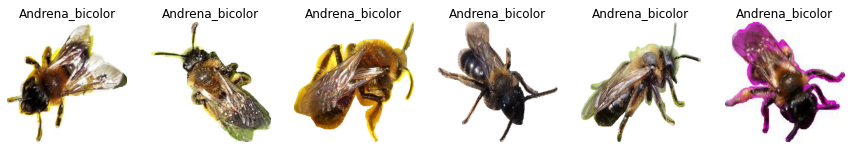

In [10]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(classes[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [11]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


2024-02-29 12:17:32.660831: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


#### Load Random Images

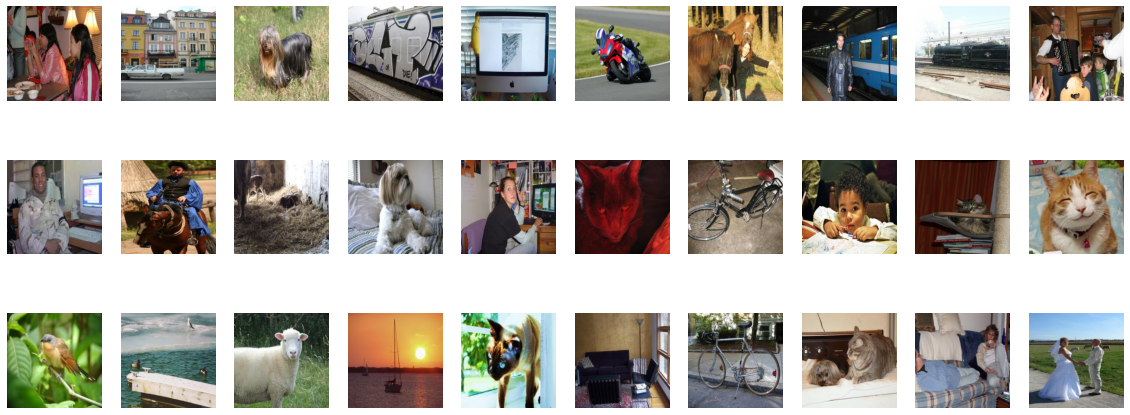

In [12]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([img/255.0 for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

#### Concept Images

There will be two concept sets:
* one for color (brown, orange, yellow)
* one for texture (fuzzy, smooth)

##### Color

In [13]:
# Store concepts, image paths and create label vector from subfolder names
colors, color_files, y_true_col = [], [], []
color_subfolders = sorted( glob.glob(CONCEPTS_PATH + 'color/*') )
for i in range(len(color_subfolders)):
    # Add color from subfolder base name
    color = os.path.basename(color_subfolders[i])
    colors.append( color )

    # Get image paths in current color subfolder (there are .jpg and .png files)
    c_files = glob.glob(CONCEPTS_PATH + 'color/' + color + '/*.jpg') + glob.glob(CONCEPTS_PATH + color + '/*.png')
    color_files += [c[len(CONCEPTS_PATH):] for c in c_files] # remove the constant path to the common dir.
    y_true_col += [i] * len(c_files)
colors

['brown', 'orange', 'yellow']

In [14]:
# Define file ids (for consistency with the parsers in the pipeline)
# Note: the metafile readers return a Dict[str, str]
file_ids_col = [str(i) for i in range(1, len(y_true_col)+1)]

In [15]:
# Get dictionary of file IDs and file names
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_col, color_files),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, CONCEPTS_PATH),
                                          label)

In [16]:
# Conversion to tf.Dataset
color_set = ps.parse_to_dataset(file_ids_col, y_true_col, parse_image_lab)
color_set = color_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
color_set = color_set.map(lambda x, y: (normalization_layer(x), y))

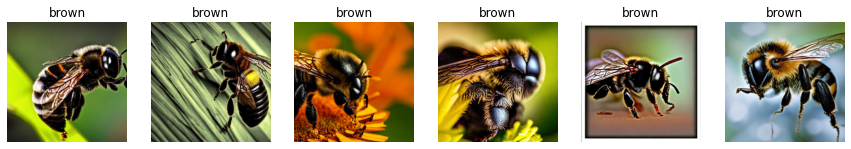

In [17]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in color_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(colors[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [18]:
for image_batch, labels_batch in color_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=int32)


Mapping relevant concepts to true class labels

In [19]:
# One-hot-encode the concepts
# Last basis vector is for random
col_basis = OneHotEncoder().fit_transform([[0], [1], [2], [3]]).toarray()
# A. bicolor:  brown + orange | B. lucorum:  yellow
# A. flavipes: brown          | B. pratorum: orange + yellow
# A. fulva:    orange
lookup_cls_colors = [col_basis[0] + col_basis[1],
                     col_basis[0],
                     col_basis[1],
                     col_basis[2],
                     col_basis[1] + col_basis[2]]
lookup_cls_colors[0]

array([1., 1., 0., 0.])

##### Texture

In [20]:
# Store concepts, image paths and create label vector from subfolder names
textures, texture_files, y_true_tex = [], [], []
texture_subfolders = sorted( glob.glob(CONCEPTS_PATH + 'texture/*') )
for i in range(len(texture_subfolders)):
    # Add texture from subfolder base name
    texture = os.path.basename(texture_subfolders[i])
    textures.append( texture )

    # Get image paths in current texture subfolder (there are .jpg and .png files)
    c_files = glob.glob(CONCEPTS_PATH + 'texture/' + texture + '/*.jpg') + glob.glob(CONCEPTS_PATH + texture + '/*.png')
    texture_files += [c[len(CONCEPTS_PATH):] for c in c_files] # remove the constant path to the common dir.
    y_true_tex += [i] * len(c_files)
textures

['fuzzy', 'smooth']

In [21]:
# Define file ids (for consistency with the parsers in the pipeline)
# Note: the metafile readers return a Dict[str, str]
file_ids_tex = [str(i) for i in range(1, len(y_true_tex)+1)]

In [22]:
# Get dictionary of file IDs and file names
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_tex, texture_files),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, CONCEPTS_PATH),
                                          label)

In [23]:
# Conversion to tf.Dataset
texture_set = ps.parse_to_dataset(file_ids_tex, y_true_tex, parse_image_lab)
texture_set = texture_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
texture_set = texture_set.map(lambda x, y: (normalization_layer(x), y))

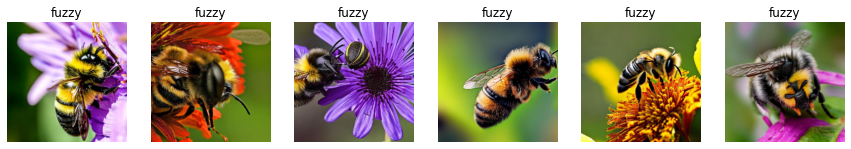

In [24]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in texture_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(textures[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [25]:
for image_batch, labels_batch in texture_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(60, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=int32)


Mapping relevant concepts to true class labels

In [26]:
# One-hot-encode the concepts
# Last basis vector is for random
texture_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
# A. bicolor:  fuzzy + smooth | B. lucorum:  fuzzy
# A. flavipes: fuzzy + smooth | B. pratorum: fuzzy
# A. fulva:    fuzzy
lookup_cls_textures = [texture_basis[0] + texture_basis[1],
                       texture_basis[0] + texture_basis[1],
                       texture_basis[0],
                       texture_basis[0],
                       texture_basis[0]]
lookup_cls_textures[0]

array([1., 1., 0.])

### Load Model

In [27]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'masked_bbox' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_5spec_2'

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [28]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/' + spec_subfolder + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

In [29]:
# Extract features for all samples
test_activations = cnn.resnet.predict(test_set)
test_activations.shape

2024-02-29 12:17:41.738684: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-02-29 12:17:42.224062: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-29 12:17:42.225213: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-29 12:17:42.225271: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-02-29 12:17:42.226456: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-29 12:17:42.226552: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


(216, 2048)

### XAI: Predict Colors

In [30]:
# Concatenate concepts and random dataset
col_rand_set = []
for img, _ in color_set.unbatch().as_numpy_iterator():
    col_rand_set.append(img)
col_rand_set = np.asarray(col_rand_set)
col_rand_set = np.concatenate((col_rand_set, random_dataset))
print(col_rand_set.shape)

y_true_col_rand = np.concatenate((y_true_col, np.array([len(colors)]*len(random_dataset))))
print(y_true_col_rand.shape)

(1090, 224, 224, 3)
(1090,)


In [31]:
# Extract features of mixed sets
res_col_rand = cnn.resnet.predict(col_rand_set)
tf.shape(res_col_rand)

<tf.Tensor: shape=(2,), dtype=int32, numpy=array([1090, 2048], dtype=int32)>

In [32]:
# Fit multiple kNNs for multiple random partitions of the random set
k = 4 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 30 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(colors)+1)) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(file_ids_col), len(col_rand_set)), 500,
                                   replace = False)

    # Overall index vector (concept indexes, then current random subset indexes)
    con_rand_ids = np.concatenate( (np.arange(len(file_ids_col)), random_ids) )

    # Fit a kNN on current partition
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(res_col_rand[con_rand_ids], y_true_col_rand[con_rand_ids])

    # Predict concepts for all test vectors
    knn_probs += neigh.predict_proba(test_activations)

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[0.24166667, 0.        , 0.15      , 0.60833333],
       [0.05      , 0.        , 0.24166667, 0.70833333],
       [0.1       , 0.        , 0.05      , 0.85      ],
       [0.01666667, 0.25      , 0.14166667, 0.59166667],
       [0.225     , 0.        , 0.21666667, 0.55833333],
       [0.25      , 0.        , 0.35      , 0.4       ],
       [0.2       , 0.        , 0.025     , 0.775     ],
       [0.25      , 0.25      , 0.375     , 0.125     ],
       [0.54166667, 0.        , 0.25      , 0.20833333],
       [0.00833333, 0.        , 0.025     , 0.96666667],
       [0.25      , 0.        , 0.10833333, 0.64166667],
       [0.14166667, 0.        , 0.025     , 0.83333333],
       [0.26666667, 0.        , 0.1       , 0.63333333],
       [0.225     , 0.        , 0.25      , 0.525     ],
       [0.35      , 0.025     , 0.        , 0.625     ],
       [0.33333333, 0.        , 0.01666667, 0.65      ],
       [0.41666667, 0.        , 0.05833333, 0.525     ],
       [0.58333333, 0.        ,

##### Offline metrics and mean scores per class

In [33]:
probs_cls_dict = {}
for c in classes:
    probs_cls_dict[c] = np.mean(knn_probs[np.where(y_true_bees == classes.index(c))], axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_colors[classes.index(c)]
    # Compute cosine sim.
    cos_sim = cosine_similarity(true_con.reshape(1, -1), probs_cls_dict[c].reshape(1, -1))[0][0]
    # Compute binary cross entropy
    bce = log_loss(true_con, probs_cls_dict[c])

    print(c)
    print('Cosine Similarity:')
    print(cos_sim)
    print('BCE:')
    print(bce); print()

Andrena_bicolor
Cosine Similarity:
0.2643244747557189
BCE:
1.5015262190476244

Andrena_flavipes
Cosine Similarity:
0.7550053416151201
BCE:
0.3332227003455614

Andrena_fulva
Cosine Similarity:
0.197099412295867
BCE:
0.8676794923186641

Bombus_lucorum
Cosine Similarity:
0.4077385604934589
BCE:
0.6244829136500951

Bombus_pratorum
Cosine Similarity:
0.698594675210695
BCE:
1.0043261318515646



In [34]:
probs_cls_dict

{'Andrena_bicolor': array([0.2175    , 0.03444444, 0.12305556, 0.625     ]),
 'Andrena_flavipes': array([0.49722222, 0.        , 0.07805556, 0.42472222]),
 'Andrena_fulva': array([0.02472222, 0.16055556, 0.01666667, 0.79805556]),
 'Bombus_lucorum': array([0.19565972, 0.28993056, 0.20772569, 0.30668403]),
 'Bombus_pratorum': array([0.12361111, 0.04277778, 0.61472222, 0.21888889])}

In [35]:
probs_con_dict = {}
for c in colors:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][colors.index(c)]
probs_con_dict

{'brown': array([0.2175    , 0.49722222, 0.02472222, 0.19565972, 0.12361111]),
 'orange': array([0.03444444, 0.        , 0.16055556, 0.28993056, 0.04277778]),
 'yellow': array([0.12305556, 0.07805556, 0.01666667, 0.20772569, 0.61472222])}

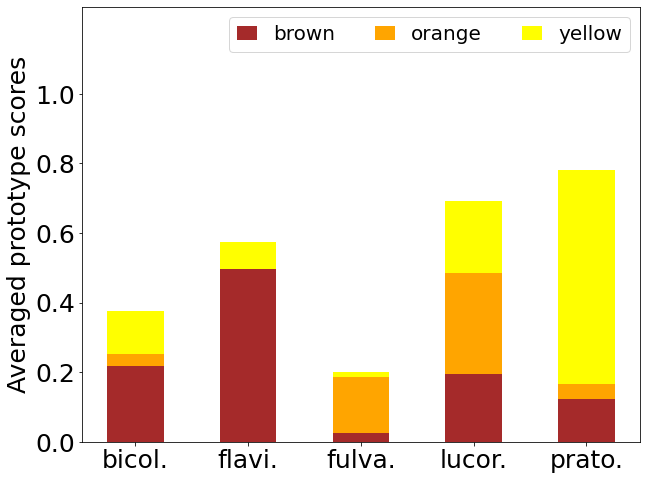

In [36]:
# Multiple random partitions
con_colors = ['brown', 'orange', 'yellow']
fontsize = 25
width = 0.5
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=width, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.25)
plt.legend(colors, loc='upper right', fontsize=fontsize-5, handlelength=1.0, ncol=3)
plt.xticks(np.arange(0.0, 10*width, width*2),
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Averaged prototype scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_bees_knn_col.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [37]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_bees == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(colors)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(colors)][0], axis=1),
                                               (len(colors),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'Andrena_bicolor': array([0.66666667, 0.1       , 0.23333333]),
 'Andrena_flavipes': array([0.8, 0. , 0.2]),
 'Andrena_fulva': array([0.3       , 0.73333333, 0.1       ]),
 'Bombus_lucorum': array([0.28125   , 0.55208333, 0.47916667]),
 'Bombus_pratorum': array([0.13333333, 0.        , 0.9       ])}

In [38]:
sig_con_dict = {}
for c in colors:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][colors.index(c)]
sig_con_dict

{'brown': array([0.66666667, 0.8       , 0.3       , 0.28125   , 0.13333333]),
 'orange': array([0.1       , 0.        , 0.73333333, 0.55208333, 0.        ]),
 'yellow': array([0.23333333, 0.2       , 0.1       , 0.47916667, 0.9       ])}

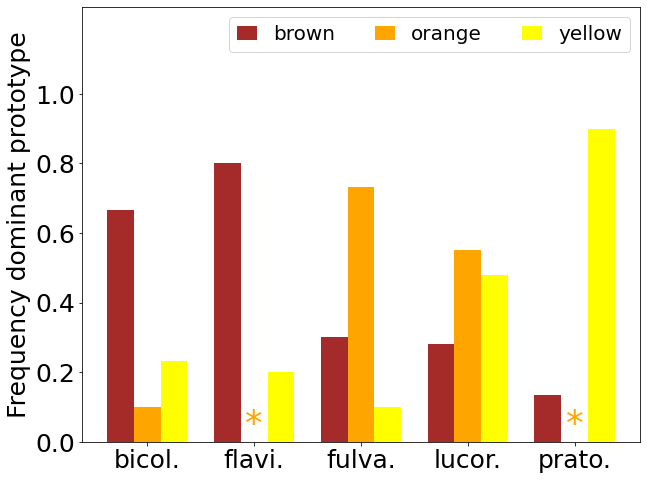

In [39]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
fontsize = 25
multiplier = 0
con_colors = ['brown', 'orange', 'yellow']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.ylim(0.0, 1.25)
plt.legend(colors, loc='upper right', fontsize=fontsize-5, handlelength=1.0, ncol=3)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/bees_knn_freq_col.png', bbox_inches='tight')
plt.show()

### XAI: Predict Colors

In [40]:
# Concatenate concepts and random dataset
tex_rand_set = []
for img, _ in texture_set.unbatch().as_numpy_iterator():
    tex_rand_set.append(img)
tex_rand_set = np.asarray(tex_rand_set)
tex_rand_set = np.concatenate((tex_rand_set, random_dataset))
print(tex_rand_set.shape)

y_true_tex_rand = np.concatenate((y_true_tex, np.array([len(textures)]*len(random_dataset))))
print(y_true_tex_rand.shape)

(1060, 224, 224, 3)
(1060,)


In [41]:
# Extract features of mixed sets
res_tex_rand = cnn.resnet.predict(tex_rand_set)
tf.shape(res_tex_rand)

<tf.Tensor: shape=(2,), dtype=int32, numpy=array([1060, 2048], dtype=int32)>

In [42]:
# Fit multiple kNNs for multiple random partitions of the random set
k = 4 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 30 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(textures)+1)) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(file_ids_tex), len(tex_rand_set)), 500,
                                   replace = False)

    # Overall index vector (concept indexes, then current random subset indexes)
    con_rand_ids = np.concatenate( (np.arange(len(file_ids_tex)), random_ids) )

    # Fit a kNN on current partition
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(res_tex_rand[con_rand_ids], y_true_tex_rand[con_rand_ids])

    # Predict concepts for all test vectors
    knn_probs += neigh.predict_proba(test_activations)

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[0.00833333, 0.025     , 0.96666667],
       [0.        , 0.025     , 0.975     ],
       [0.        , 0.        , 1.        ],
       [0.        , 0.25      , 0.75      ],
       [0.        , 0.        , 1.        ],
       [0.        , 0.05      , 0.95      ],
       [0.        , 0.01666667, 0.98333333],
       [0.5       , 0.36666667, 0.13333333],
       [0.        , 1.        , 0.        ],
       [0.03333333, 0.15833333, 0.80833333],
       [0.11666667, 0.025     , 0.85833333],
       [0.        , 0.        , 1.        ],
       [0.20833333, 0.00833333, 0.78333333],
       [0.        , 0.225     , 0.775     ],
       [0.        , 0.        , 1.        ],
       [0.        , 0.        , 1.        ],
       [0.        , 0.03333333, 0.96666667],
       [0.75      , 0.        , 0.25      ],
       [0.        , 0.        , 1.        ],
       [0.        , 0.08333333, 0.91666667],
       [0.        , 0.00833333, 0.99166667],
       [0.09166667, 0.5       , 0.40833333],
       [0.

##### Offline metrics and mean scores per class

In [43]:
probs_cls_dict = {}
for c in classes:
    probs_cls_dict[c] = np.mean(knn_probs[np.where(y_true_bees == classes.index(c))], axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_textures[classes.index(c)]
    # Compute cosine sim.
    cos_sim = cosine_similarity(true_con.reshape(1, -1), probs_cls_dict[c].reshape(1, -1))[0][0]
    # Compute binary cross entropy
    bce = log_loss(true_con, probs_cls_dict[c])

    print(c)
    print('Cosine Similarity:')
    print(cos_sim)
    print('BCE:')
    print(bce); print()

Andrena_bicolor
Cosine Similarity:
0.14813445349098406
BCE:
2.248416135294734

Andrena_flavipes
Cosine Similarity:
0.6070982345711066
BCE:
11.82507708486655

Andrena_fulva
Cosine Similarity:
0.01813899752591692
BCE:
2.46681126823026

Bombus_lucorum
Cosine Similarity:
0.9018805986897717
BCE:
0.3134405223410894

Bombus_pratorum
Cosine Similarity:
0.9747231747354757
BCE:
0.1570197467054535



In [44]:
probs_cls_dict

{'Andrena_bicolor': array([0.05694444, 0.11805556, 0.825     ]),
 'Andrena_flavipes': array([0.        , 0.62611111, 0.37388889]),
 'Andrena_fulva': array([0.0175    , 0.01805556, 0.96444444]),
 'Bombus_lucorum': array([0.60789931, 0.13315972, 0.25894097]),
 'Bombus_pratorum': array([0.78694444, 0.03638889, 0.17666667])}

In [45]:
probs_con_dict = {}
for c in textures:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][textures.index(c)]
probs_con_dict

{'fuzzy': array([0.05694444, 0.        , 0.0175    , 0.60789931, 0.78694444]),
 'smooth': array([0.11805556, 0.62611111, 0.01805556, 0.13315972, 0.03638889])}

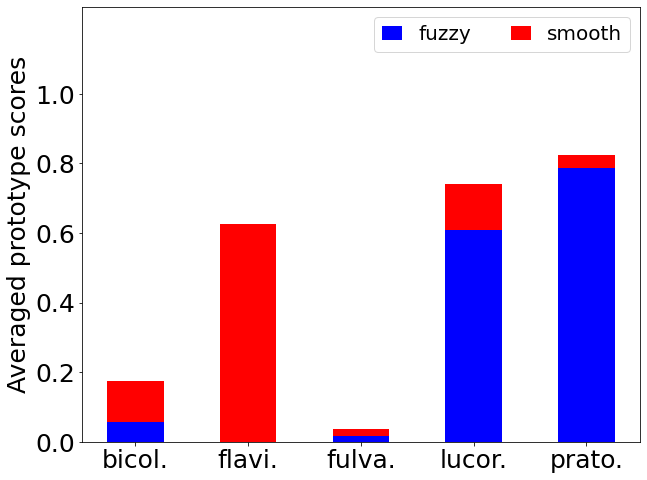

In [46]:
# Multiple random partitions
con_colors = ['blue', 'red']
fontsize = 25
width = 0.5
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=width, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.25)
plt.legend(textures, loc='upper right', fontsize=fontsize-5, handlelength=1.0, ncol=3)
plt.xticks(np.arange(0.0, 10*width, width*2),
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Averaged prototype scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_bees_knn_tex.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [47]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_bees == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(colors)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(textures)][0], axis=1),
                                               (len(colors),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'Andrena_bicolor': array([0.43333333, 0.86666667, 0.        ]),
 'Andrena_flavipes': array([0., 1., 0.]),
 'Andrena_fulva': array([0.93333333, 0.56666667, 0.03333333]),
 'Bombus_lucorum': array([0.95833333, 0.125     , 0.        ]),
 'Bombus_pratorum': array([0.96666667, 0.03333333, 0.        ])}

In [48]:
sig_con_dict = {}
for c in textures:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][textures.index(c)]
sig_con_dict

{'fuzzy': array([0.43333333, 0.        , 0.93333333, 0.95833333, 0.96666667]),
 'smooth': array([0.86666667, 1.        , 0.56666667, 0.125     , 0.03333333])}

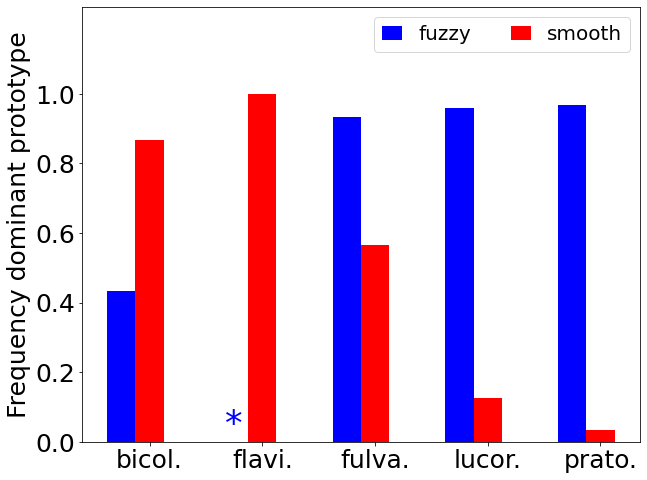

In [49]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
fontsize = 25
multiplier = 0
con_colors = ['blue', 'red']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x+width,
           [c.split('_')[1][:5]+'.' for c in classes],
           fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.ylim(0.0, 1.25)
plt.legend(textures, loc='upper right', fontsize=fontsize-5, handlelength=1.0, ncol=3)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/bees_knn_freq_tex.png', bbox_inches='tight')
plt.show()